# Bài 2 – Khảo sát MLP – PyTorch

Bám theo mã giảng viên: **1200 mẫu make_moons, noise=0.28, 15 epoch**,
train/validation **960/240**, batch train 32, seed 42.
Đề tham chiếu: `../Buoi1/bai1.txt`.

Chọn kernel Python của `Buoi1_PyTorch/.venv`, rồi **Run All**. Kết quả đã lưu sẵn trong notebook.
`common.py` mới phải nằm cùng thư mục. Các cấu hình giữ đúng như script cùng tên.

## 1. Thư viện và tham số

MLP nhận hai tọa độ, qua các tầng ẩn rồi xuất hai logits cho hai lớp.
CrossEntropyLoss đo sai số; Adam cập nhật trọng số qua lan truyền ngược.
Một epoch là một lượt học qua toàn bộ train. Giữ số epoch theo mã mẫu.

In [1]:
from pathlib import Path
from dataclasses import asdict
from time import perf_counter
import sys
import itertools

cwd = Path.cwd().resolve()
paths = [cwd, cwd / "Buoi1_PyTorch", *[p / "Buoi1_PyTorch" for p in cwd.parents]]
BASE = next((p for p in paths if (p / "common.py").is_file() and p.name == "Buoi1_PyTorch"), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook từ repository DeepL hoặc thư mục Buoi1_PyTorch.")
sys.path.insert(0, str(BASE))
# Tránh dùng nhầm common.py của bản cũ khi trước đó mở notebook khác.
if "common" in sys.modules and Path(sys.modules["common"].__file__).resolve() != BASE / "common.py":
    del sys.modules["common"]

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from IPython.display import display, Markdown, Image
from common import Config, seed_everything, build_mlp, evaluate, save_results

%matplotlib inline
print("PyTorch:", torch.__version__)

PyTorch: 2.14.1+cpu


In [2]:
EPOCHS = 15
VAL_BATCH_SIZE = 256
OUTPUT_DIR = BASE / 'results' / 'bai2'

## 2. Dữ liệu

Giữ `random_split` và dữ liệu thô như mã ban đầu. Train dùng để học,
validation dùng để theo dõi và so sánh. Không thêm tập test hay StandardScaler.

Train: 960; validation: 240


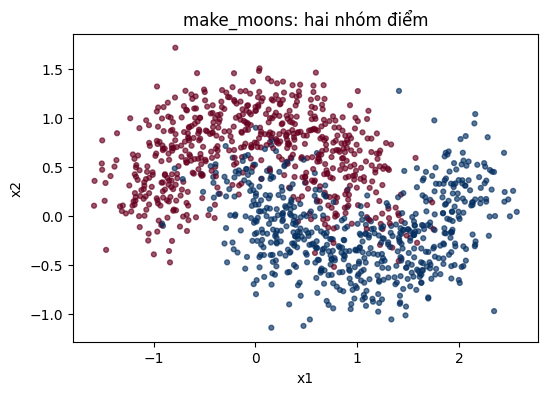

In [3]:
seed_everything(42)
X, y = make_moons(n_samples=1200, noise=0.28, random_state=42)
ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
tr, va = random_split(ds, [960, 240], generator=torch.Generator().manual_seed(42))
print(f"Train: {len(tr)}; validation: {len(va)}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", s=12, alpha=0.65)
ax.set(title="make_moons: hai nhóm điểm", xlabel="x1", ylabel="x2")
plt.show()

## 3. Cấu hình so sánh

Giữ khảo sát hidden size × LR của mã BTVN: **8/32/64**, LR **0.01/0.001**;
bổ sung độ rộng **128** để đối chiếu với Bài 1.

Baseline mở rộng: **hai tầng × 32 neuron, ReLU, LR=0.001**. Mỗi cấu hình mới
chỉ đổi một yếu tố: số tầng 1/3, tanh/sigmoid, Dropout 0.2 hoặc Weight Decay 0.0001.
Dropout tắt ngẫu nhiên neuron khi học; Weight Decay hạn chế trọng số lớn.

In [4]:
configs = [Config(f'width{hidden}_lr{lr:g}', hidden=(hidden, hidden), lr=lr) for hidden, lr in itertools.product([8, 32, 64, 128], [0.01, 0.001])]
configs += [Config('depth1', hidden=(32,)), Config('depth3', hidden=(32, 32, 32)), Config('tanh', activation='tanh'), Config('sigmoid', activation='sigmoid'), Config('dropout', dropout=0.2), Config('weight_decay', weight_decay=0.0001)]

In [5]:
display(pd.DataFrame([asdict(config) for config in configs]))
print("Ví dụ mạng:")
print(build_mlp(configs[0].hidden, configs[0].activation, configs[0].dropout))

,name,hidden,activation,lr,dropout,weight_decay
0,width8_lr0.01,"(8, 8)",relu,0.010,0.0,0.0000
1,width8_lr0.001,"(8, 8)",relu,0.001,0.0,0.0000
2,width32_lr0.01,"(32, 32)",relu,0.010,0.0,0.0000
3,width32_lr0.001,"(32, 32)",relu,0.001,0.0,0.0000
4,width64_lr0.01,"(64, 64)",relu,0.010,0.0,0.0000
5,width64_lr0.001,"(64, 64)",relu,0.001,0.0,0.0000
6,width128_lr0.01,"(128, 128)",relu,0.010,0.0,0.0000
7,width128_lr0.001,"(128, 128)",relu,0.001,0.0,0.0000
8,depth1,"(32,)",relu,0.001,0.0,0.0000
9,depth3,"(32, 32, 32)",relu,0.001,0.0,0.0000


Ví dụ mạng:
Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=2, bias=True)
)


## 4. Huấn luyện

Mỗi batch: xóa gradient → dự đoán → tính loss → lan truyền ngược → cập nhật trọng số.
Sau mỗi epoch, đo train và validation ở chế độ `eval` để tắt Dropout.

Chạy đủ số epoch rồi báo cáo **mô hình cuối**, giữ cách làm đơn giản của mã mẫu.
Không chọn checkpoint sớm. Mọi cấu hình đều đặt lại seed 42 để so sánh công bằng.

In [6]:
def train_classifier(model, train_loader, val_loader, epochs=20, lr=1e-3, weight_decay=0.0):
    """Huấn luyện đủ số epoch và báo cáo mô hình cuối, không chọn checkpoint."""
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    train_eval_loader = DataLoader(train_loader.dataset, batch_size=128, shuffle=False)
    history = []
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        for X, y in train_loader:
            optimizer.zero_grad()
            logits = model(X)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
        train_metrics = evaluate(model, train_eval_loader)
        val_metrics = evaluate(model, val_loader)
        history.append({
            "epoch": epoch,
            **{f"train_{key}": value for key, value in train_metrics.items()},
            **{f"val_{key}": value for key, value in val_metrics.items()},
        })
    elapsed = perf_counter() - start
    return {
        **history[-1],
        "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "seconds": elapsed,
    }, history

In [7]:
rows, histories = [], []
for config in configs:
    seed_everything(42)
    model = build_mlp(config.hidden, config.activation, config.dropout)
    train_loader = DataLoader(
        tr, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(42),
    )
    val_loader = DataLoader(va, batch_size=VAL_BATCH_SIZE, shuffle=False)
    metrics, trace = train_classifier(
        model, train_loader, val_loader, epochs=EPOCHS,
        lr=config.lr, weight_decay=config.weight_decay,
    )
    rows.append({**asdict(config), "hidden": "x".join(map(str, config.hidden)), **metrics})
    histories.extend({"config": config.name, **record} for record in trace)
    print(f"{config.name:20} loss={metrics['val_loss']:.4f} accuracy={metrics['val_accuracy']:.2%}")

width8_lr0.01        loss=0.2722 accuracy=89.17%


width8_lr0.001       loss=0.3790 accuracy=85.42%


width32_lr0.01       loss=0.2849 accuracy=88.33%


width32_lr0.001      loss=0.2863 accuracy=89.17%


width64_lr0.01       loss=0.2783 accuracy=88.75%


...

depth3               loss=0.2688 accuracy=90.00%


tanh                 loss=0.3554 accuracy=85.83%


sigmoid              loss=0.3700 accuracy=84.17%


dropout              loss=0.3057 accuracy=87.50%


weight_decay         loss=0.2885 accuracy=88.75%


## 5. Bảng kết quả và xuất file

Loss là cross-entropy trên validation, không cộng phạt trọng số. Accuracy là tỷ lệ đúng;
Macro-F1 coi các lớp quan trọng ngang nhau. Số tham số gồm trọng số và bias.
Thời gian gồm huấn luyện và đo train/validation, không gồm vẽ hình.
Accuracy/F1 ở thang [0, 1]. Chỉ có seed 42; không lấy trung bình nhiều lần chạy.

In [8]:
results, history = save_results(
    configs, tr, va, rows, histories, epochs=EPOCHS,
    val_batch_size=VAL_BATCH_SIZE, output_dir=OUTPUT_DIR, dataset='make_moons, n_samples=1200, noise=0.28, random_state=42',
)
display(results[[
    "name", "hidden", "activation", "lr", "dropout", "weight_decay",
    "train_loss", "val_loss", "train_accuracy", "val_accuracy", "val_macro_f1", "parameters", "seconds",
]].style.format({
    "train_loss": "{:.4f}", "val_loss": "{:.4f}", "train_accuracy": "{:.4f}",
    "val_accuracy": "{:.4f}", "val_macro_f1": "{:.4f}", "seconds": "{:.2f}",
}).hide(axis="index"))

name,hidden,activation,lr,dropout,weight_decay,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1,parameters,seconds
width8_lr0.01,8x8,relu,0.010000,0.000000,0.000000,0.1895,0.2722,0.9198,0.8917,0.8916,114,0.31
width8_lr0.001,8x8,relu,0.001000,0.000000,0.000000,0.3266,0.3790,0.8688,0.8542,0.8541,114,0.31
width32_lr0.01,32x32,relu,0.010000,0.000000,0.000000,0.1799,0.2849,0.9250,0.8833,0.8832,1218,0.31
width32_lr0.001,32x32,relu,0.001000,0.000000,0.000000,0.2250,0.2863,0.9052,0.8917,0.8915,1218,0.31
width64_lr0.01,64x64,relu,0.010000,0.000000,0.000000,0.1771,0.2783,0.9240,0.8875,0.8874,4482,0.32
width64_lr0.001,64x64,relu,0.001000,0.000000,0.000000,0.1885,0.2729,0.9167,0.9000,0.8999,4482,0.32
width128_lr0.01,128x128,relu,0.010000,0.000000,0.000000,0.1786,0.2867,0.9240,0.8792,0.8791,17154,0.34
width128_lr0.001,128x128,relu,0.001000,0.000000,0.000000,0.1837,0.2725,0.9219,0.8875,0.8873,17154,0.34
depth1,32,relu,0.001000,0.000000,0.000000,0.2990,0.3525,0.8792,0.8625,0.8624,162,0.29
depth3,32x32x32,relu,0.001000,0.000000,0.000000,0.1925,0.2688,0.9135,0.9000,0.8999,2274,0.35


## 6. Biểu đồ và learning curve

**Underfitting:** cả train và validation đều chưa tốt; cũng có thể do học chưa đủ epoch.
**Overfitting:** train tiếp tục tốt lên nhưng validation xấu đi.
Đọc xu hướng thực tế; không bắt buộc phải thấy overfitting chỉ sau 15/20 epoch.

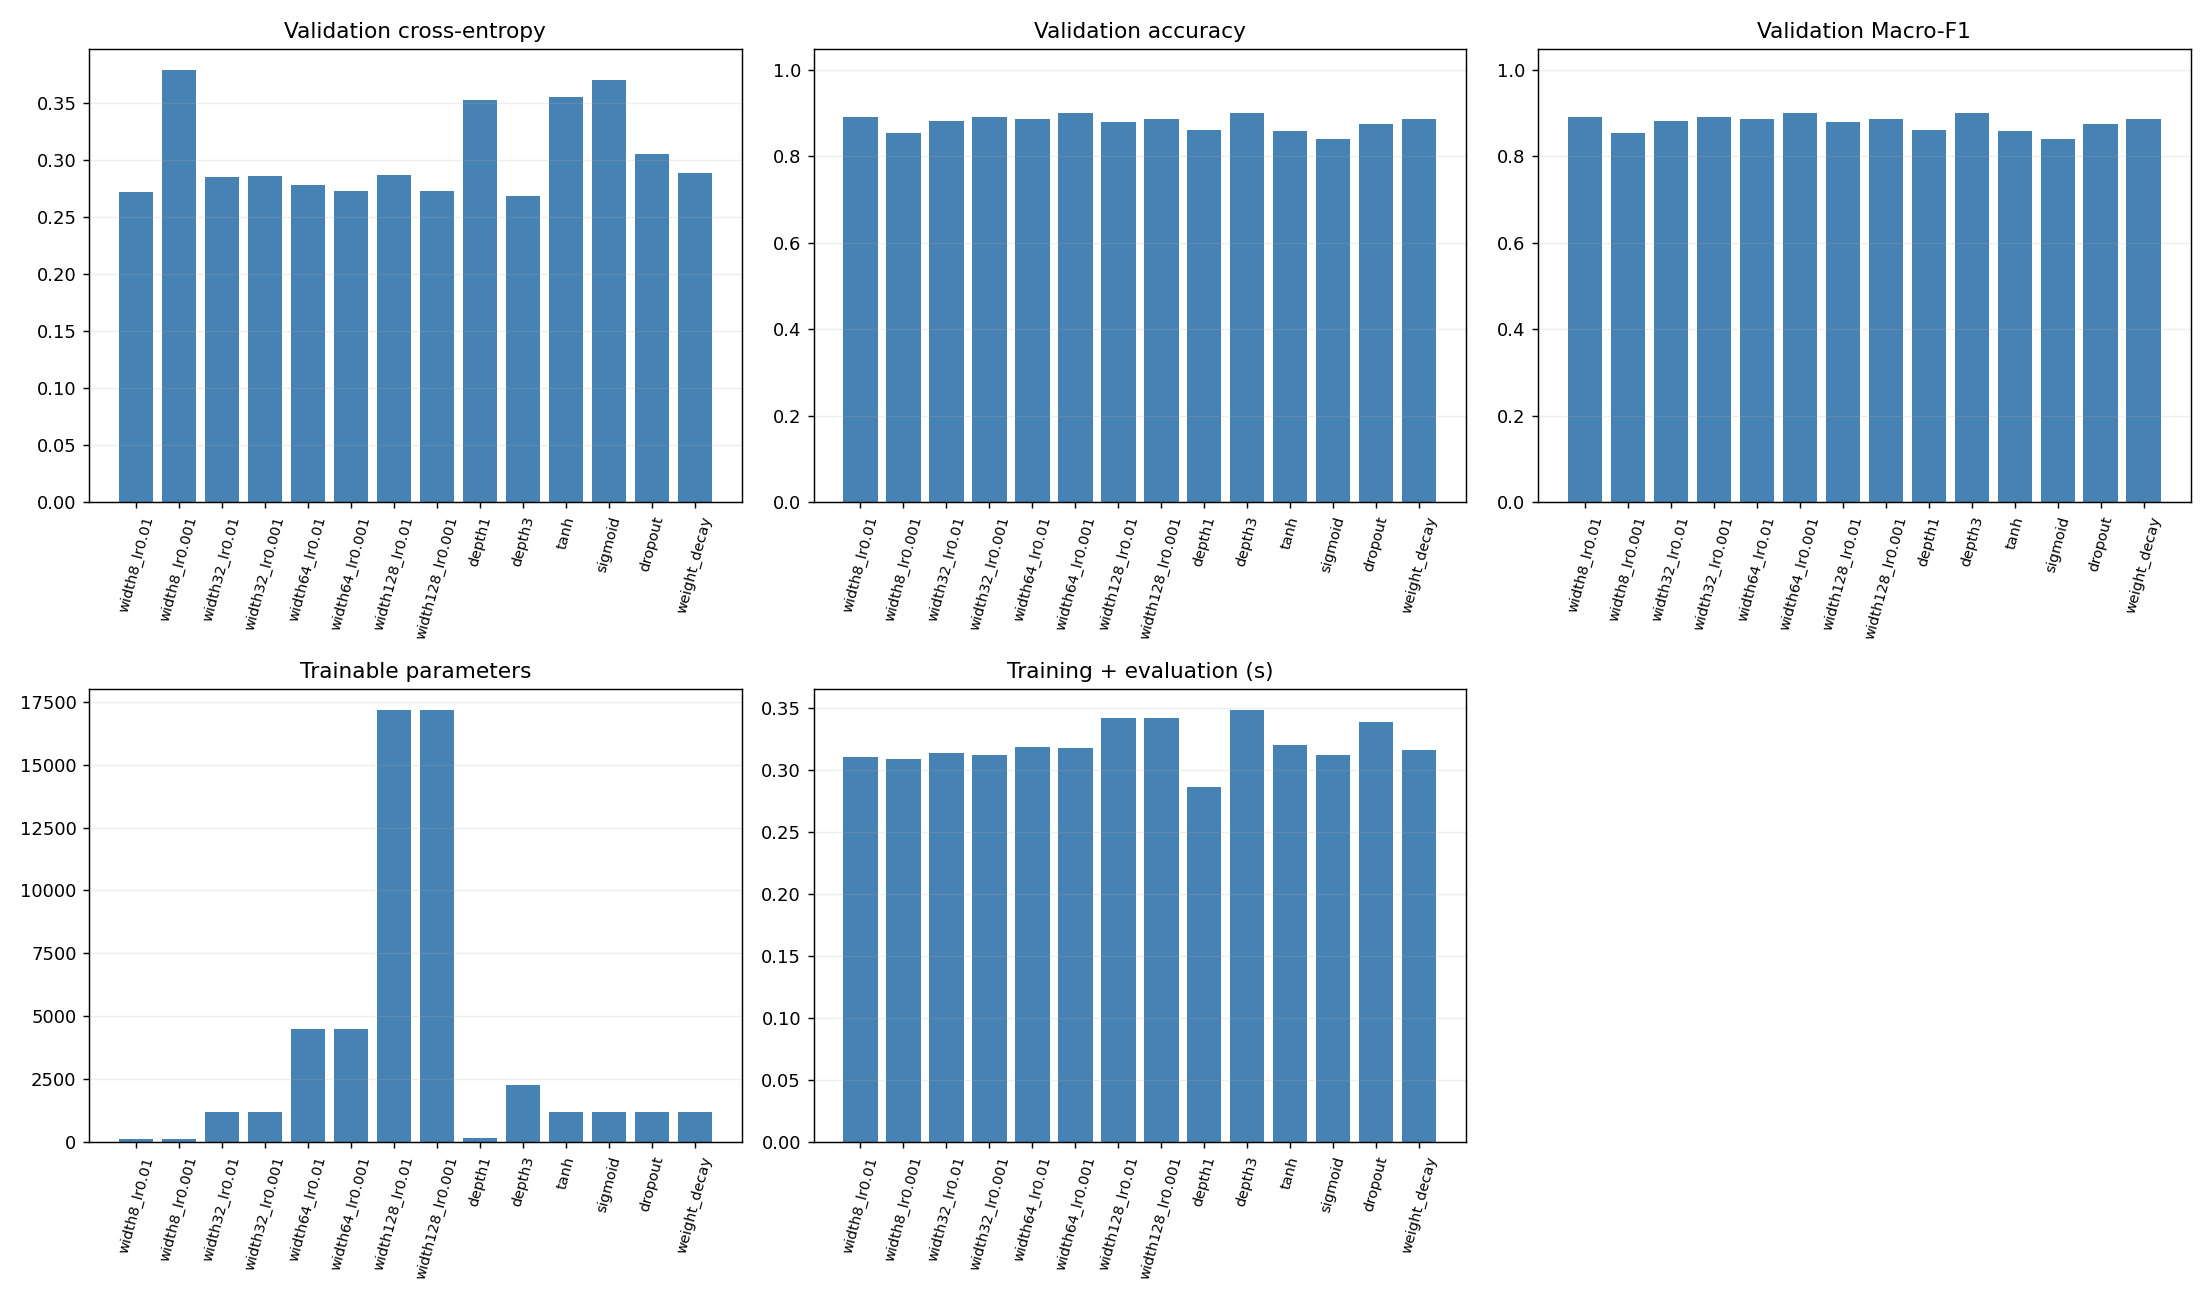

In [9]:
display(Image(filename=str(OUTPUT_DIR / "comparison.png")))

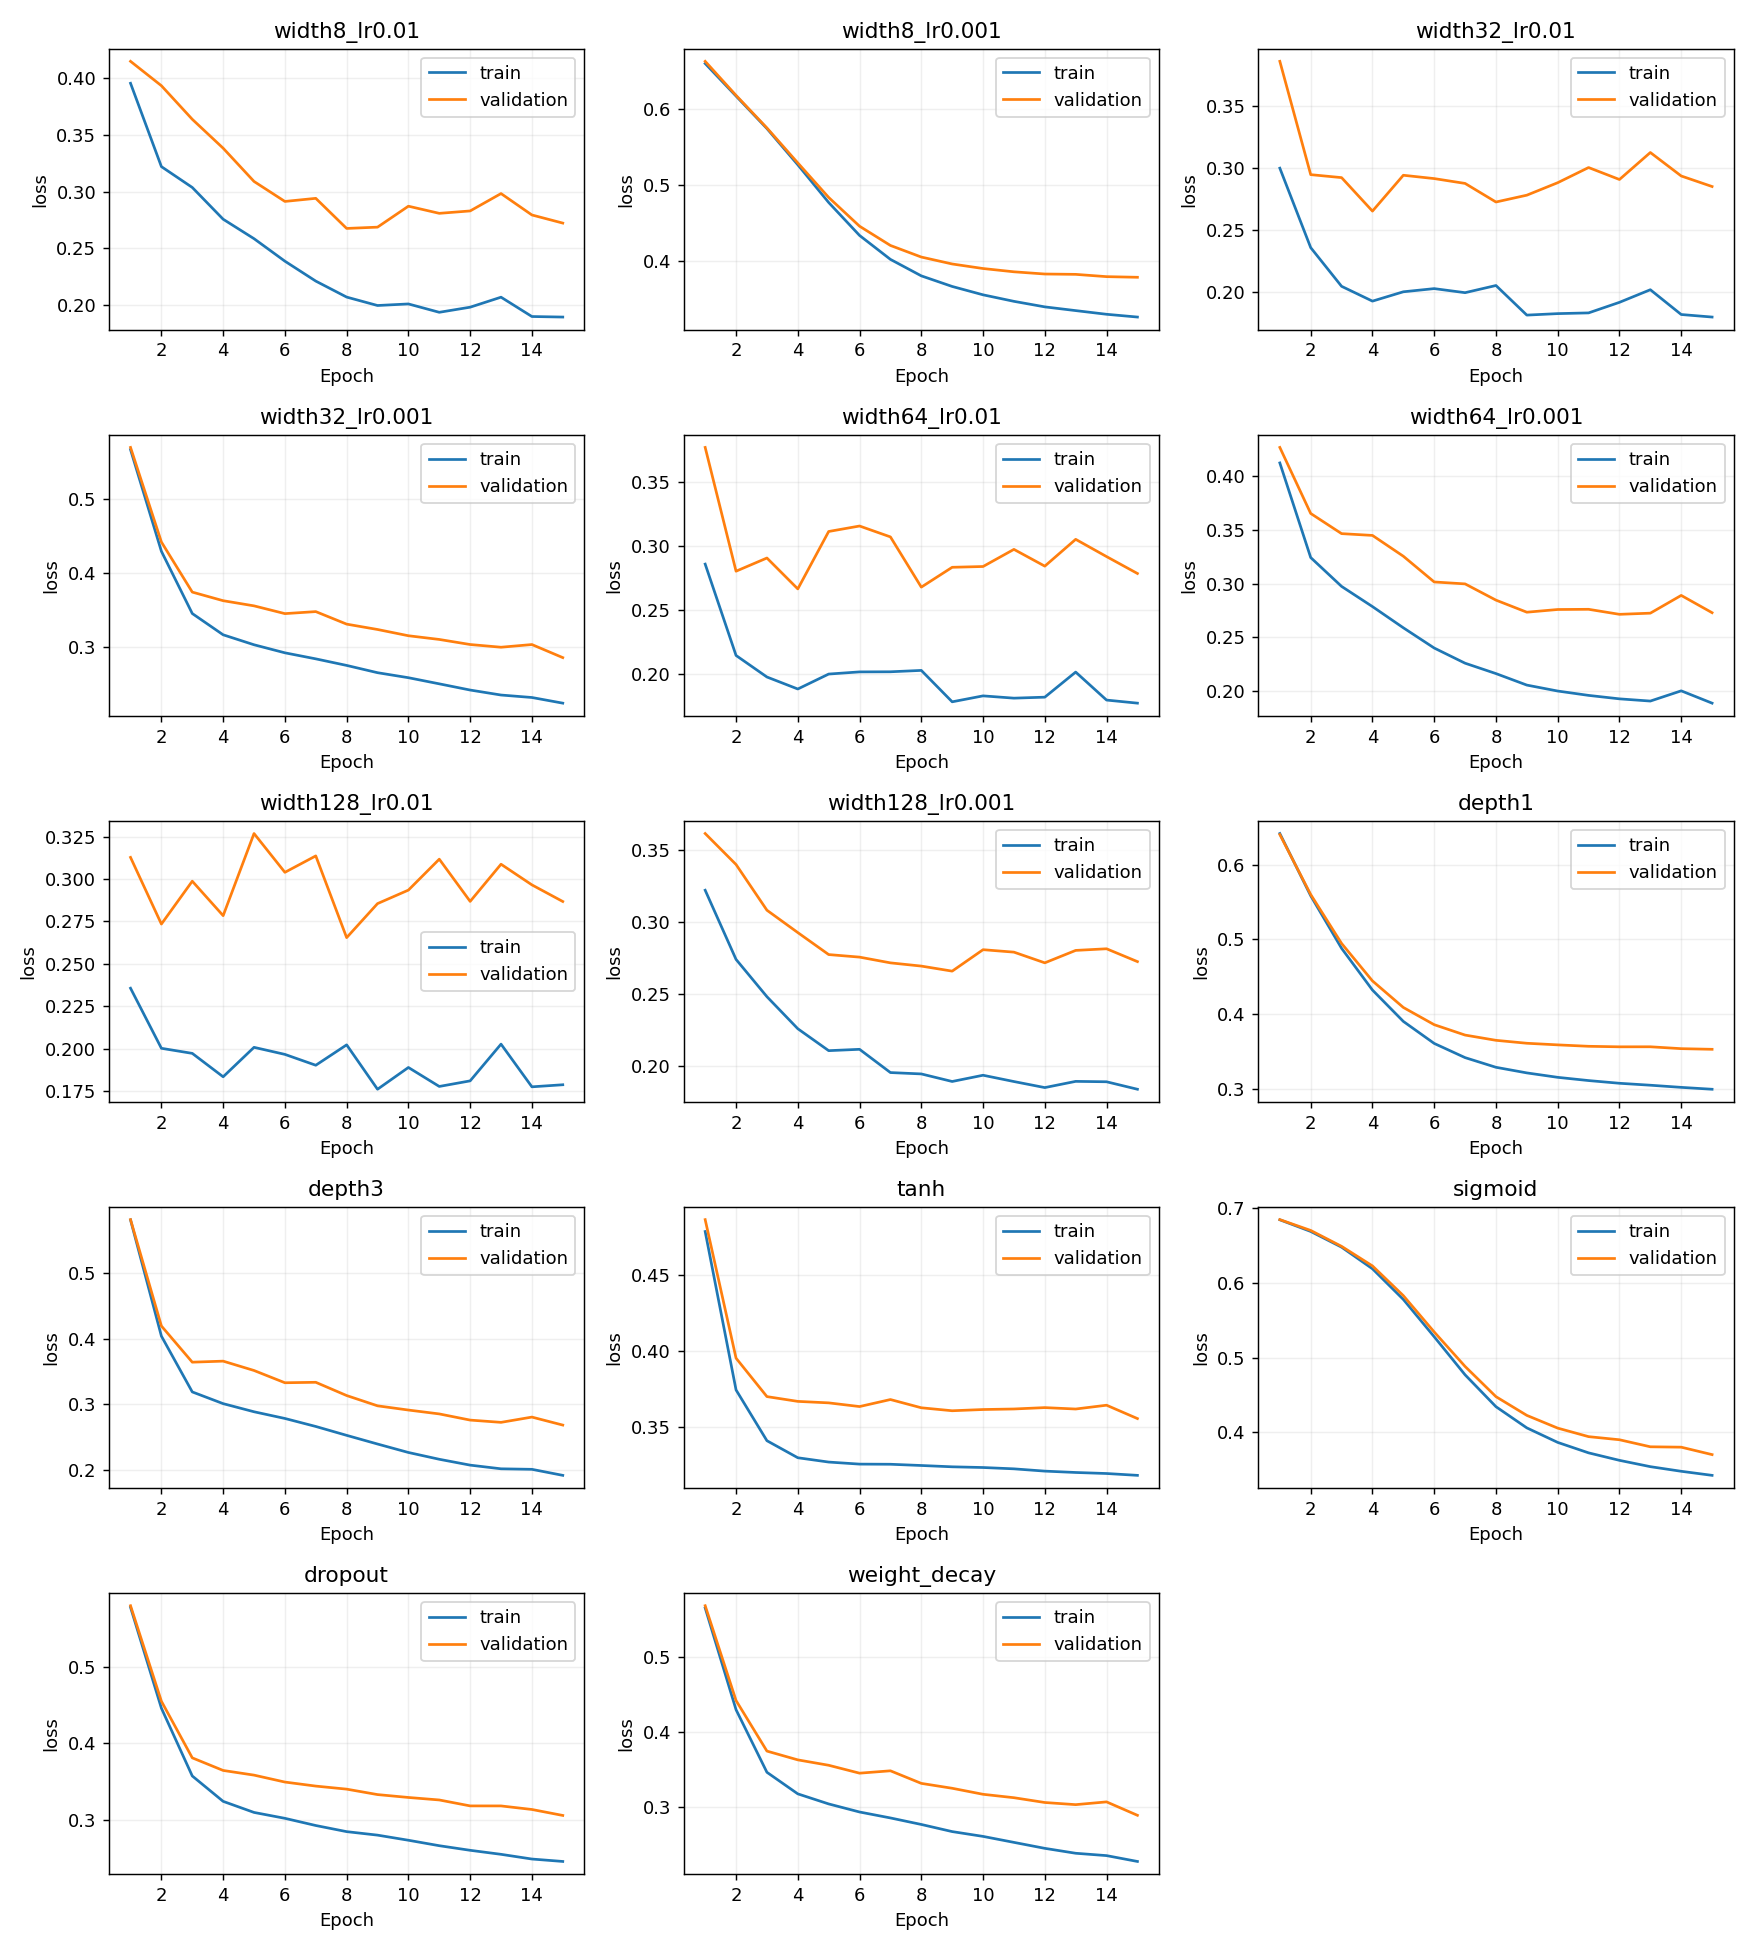

In [10]:
display(Image(filename=str(OUTPUT_DIR / "learning_loss.png")))

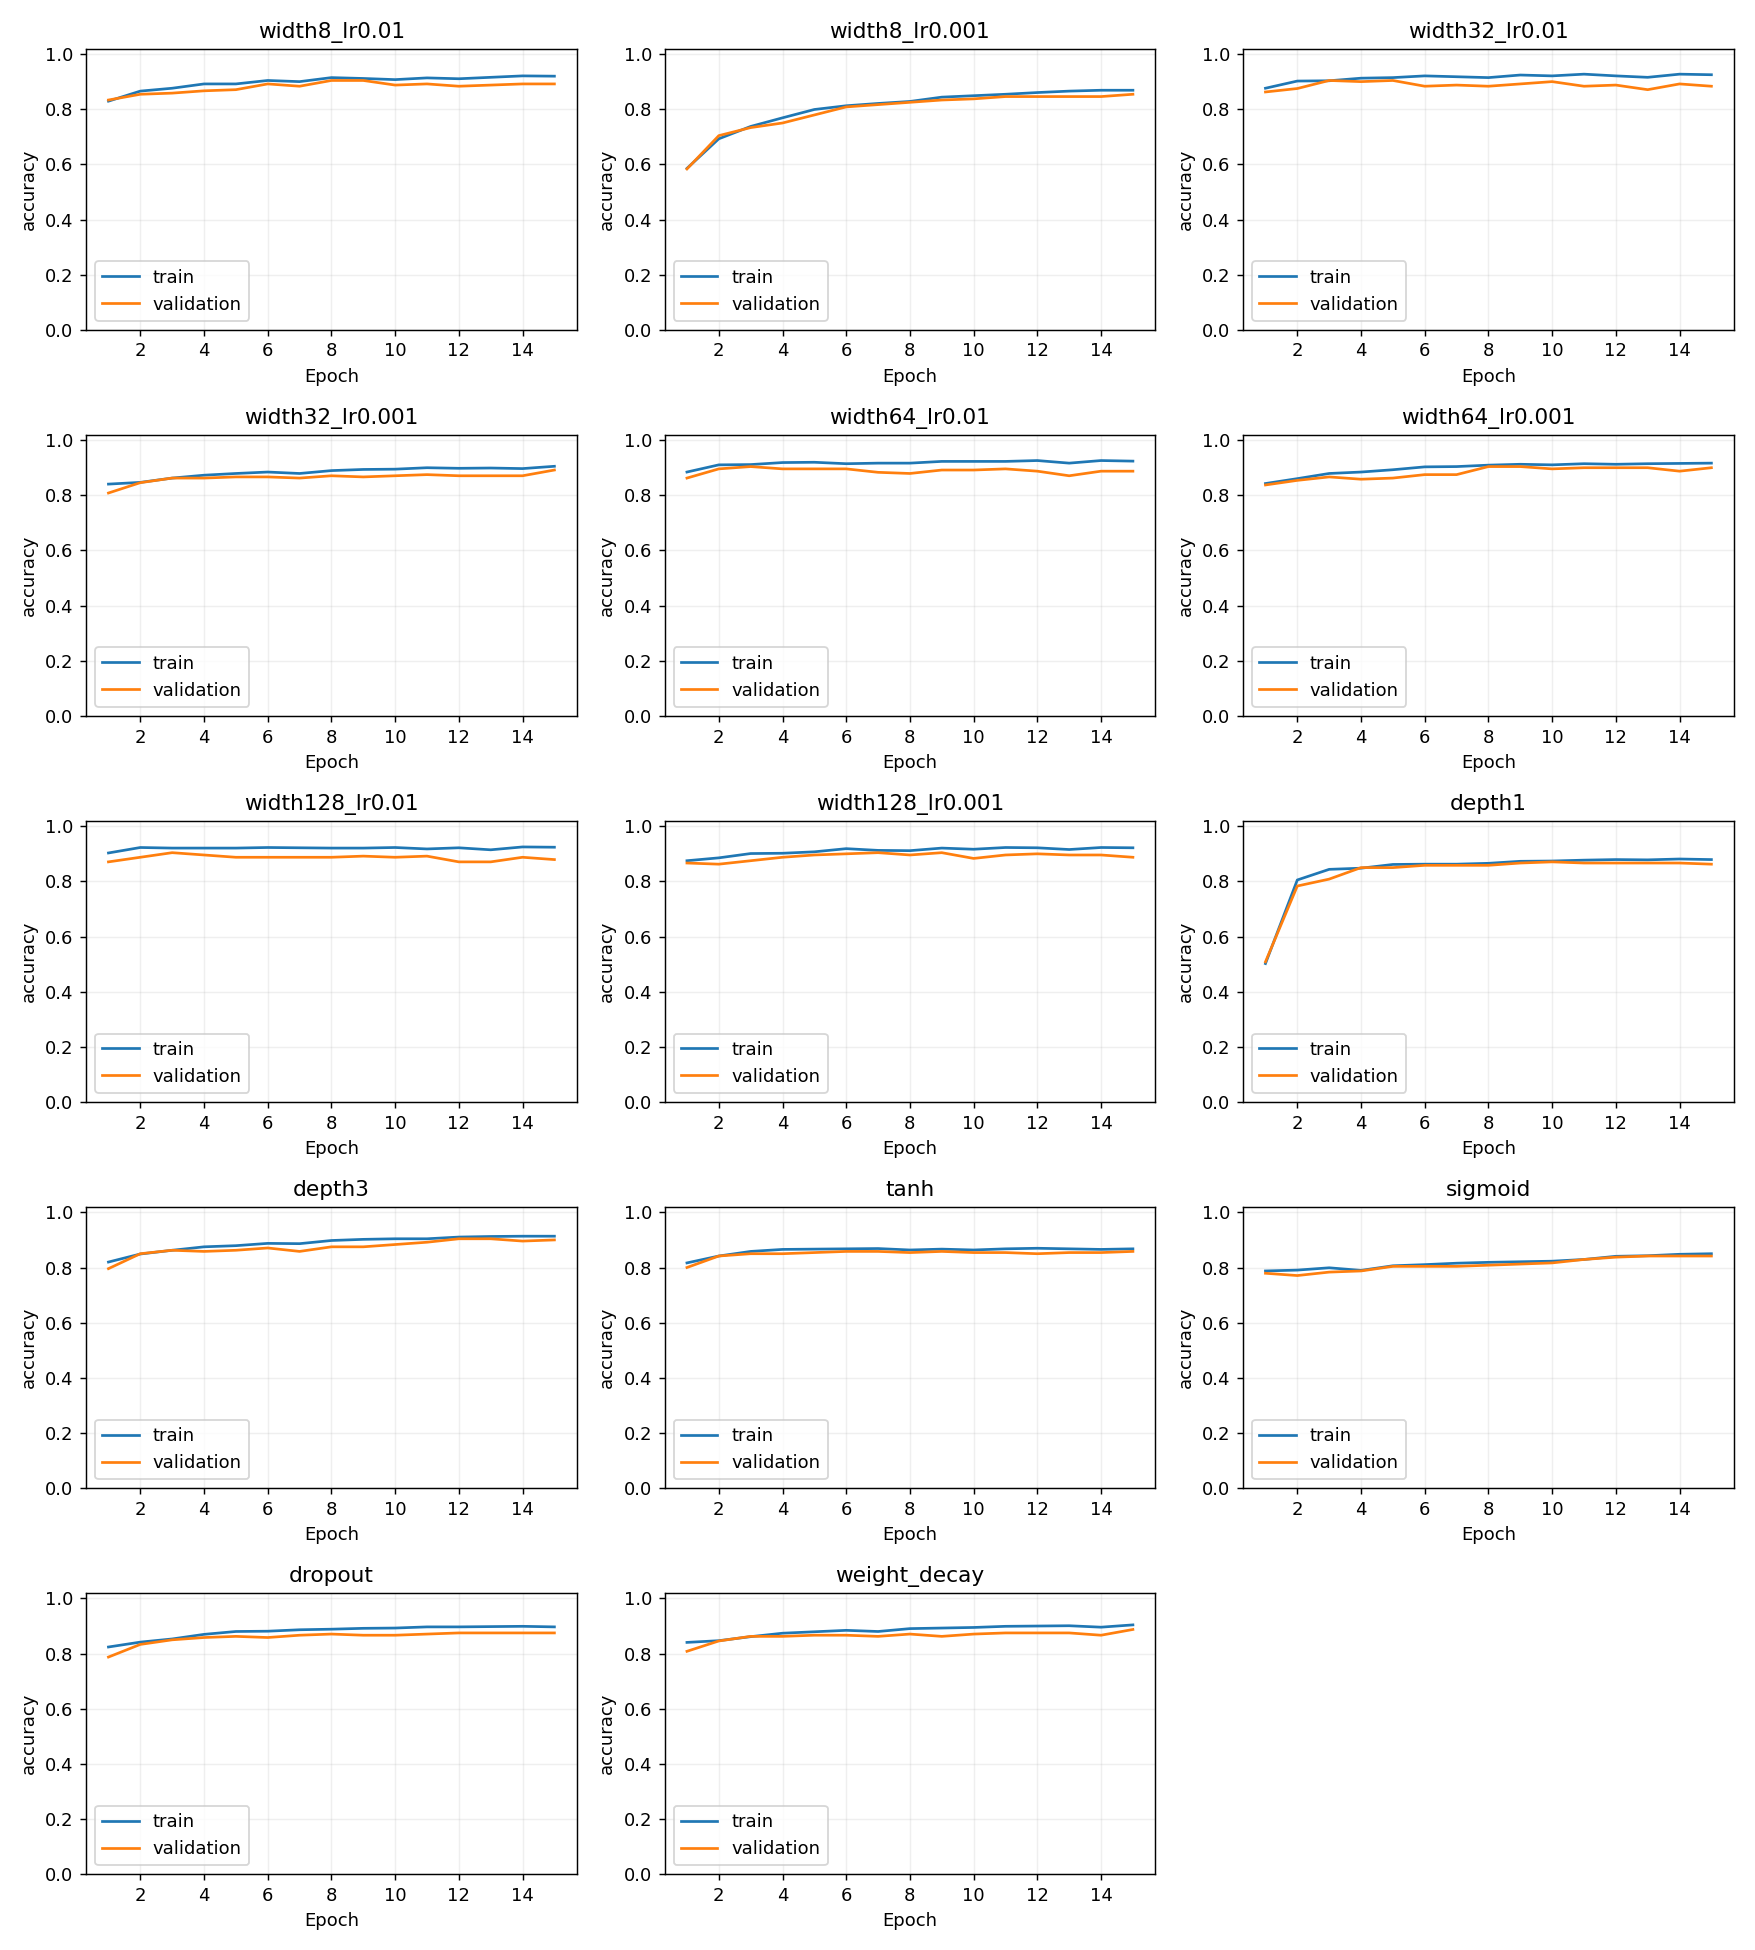

In [11]:
display(Image(filename=str(OUTPUT_DIR / "learning_accuracy.png")))

## 7. Nhận xét ngắn

Nhận xét tự cập nhật theo kết quả vừa chạy. Validation không phải test độc lập,
nên kết quả chỉ dùng cho bài khảo sát. Các ngưỡng nhận diện underfit/overfit là tham khảo.

In [12]:
report = (OUTPUT_DIR / "report.md").read_text(encoding="utf-8")
notes = report.split("## Nhận xét ngắn\n\n", 1)[1].split("\n## Biểu đồ", 1)[0]
display(Markdown(notes))

- Cấu hình có validation loss thấp nhất là **depth3** (0.2688), accuracy 90.00%, Macro-F1 0.8999.
- Số tầng ẩn 1/2/3: **depth3** có validation loss thấp nhất nhóm (0.2688).
- Số neuron tại LR=0.001: **width128_lr0.001** có validation loss thấp nhất nhóm (0.2725).
- Activation: **width32_lr0.001** có validation loss thấp nhất nhóm (0.2863).
- Regularization: **width32_lr0.001** có validation loss thấp nhất nhóm (0.2863).
- Khảo sát LR theo mã BTVN gốc: loss trung bình trên bốn độ rộng là 0.2805 với LR=0.01 và 0.3027 với LR=0.001. LR quyết định độ lớn bước cập nhật; kết luận phụ thuộc ngân sách 15 epoch.
- Dấu hiệu overfitting ở **width128_lr0.01**: sau epoch có val loss thấp nhất, train loss giảm thêm >0.005 nhưng val loss tăng >0.02.
- Cả train/validation accuracy cuối đều dưới 90% ở **width8_lr0.001, depth1, tanh, sigmoid, dropout**: có dấu hiệu học chưa đủ tốt. Đây có thể là underfitting hoặc chưa hội tụ; nếu loss vẫn giảm thì 15/20 epoch có thể chưa đủ để kết luận thiếu năng lực mô hình.
- Chỉ chạy seed 42 để sát mã mẫu. Các ngưỡng chẩn đoán là tham khảo; cần đối chiếu learning curve. Không suy rộng kết quả cho mọi dữ liệu hoặc số epoch.
